In [1]:
import pandas as pd
import pyarrow.parquet as pq
import numpy as np
import re
from sklearn.preprocessing import OneHotEncoder

In [ ]:
tabler=pq.read_table("auto.parquet")
df=tabler.to_pandas()

In [ ]:
def cleanAnomalies(dfr:pd.DataFrame):
    dfr=dfr.drop_duplicates()
    dfr=dfr[~dfr["name"].str.contains("Куплю", case=False, na=False)]
    dfr=dfr[dfr["price"]<=110213.5]
    return dfr

In [ ]:
def imputeMissingValues(dfr:pd.DataFrame):
    dfr["price"]=dfr["price"].replace(1.0, np.nan)
    dfr["price"]=dfr.groupby(["brand", "model"])["price"].transform(lambda x: x.fillna(x.median()))
    dfr["price"]=dfr.groupby("brand")["price"].transform(lambda x: x.fillna(x.median()))
    dfr["price"]=dfr["price"].fillna(dfr["price"].mean())

    dfr["engine_volume"]=dfr["engine_volume"].replace(0.0, np.nan)
    dfr["engine_volume"]=dfr.groupby(["brand", "model"])["engine_volume"].transform(lambda x: x.fillna(x.median()))
    dfr["engine_volume"]=dfr.groupby("brand")["engine_volume"].transform(lambda x: x.fillna(x.median()))
    dfr=dfr.dropna(subset=["engine_volume"])

    dfr=dfr[dfr["year"]!=0]

    dfr["mileage"]=dfr["mileage"].replace(0.0, np.nan)
    dfr["mileage"]=dfr.groupby(["brand", "model"])["mileage"].transform(lambda x: x.fillna(x.median()))
    dfr["mileage"]=dfr.groupby("brand")["mileage"].transform(lambda x: x.fillna(x.median()))
    dfr["mileage"]=dfr["mileage"].fillna(dfr["mileage"].mean())

    return dfr


In [ ]:
def fillModel(row):
    name=str(row["name"]).strip()
    brand=str(row["brand"]).strip()
    cmodel=str(row["model"]).strip()

    if(cmodel and cmodel!="nan" and cmodel!="" and not pd.isna(row["model"])):
        return row["model"]

    name_cleaned=re.sub(r"(?i)\s*[-—–]?\s*объявление\s*\d+", "", name).strip()

    if re.search(fr"(?i)^{brand}", name_cleaned):
        match=re.search(fr"(?i)^{brand}", name_cleaned)
        extracted_model=name_cleaned[match.end() :].strip()
    else:
        extracted_model=name_cleaned

    extracted_model=extracted_model.strip(", ").strip()

    garbage_pattern=(r"(?i)\b(внедорожник|седан|хэтчбек|универсал|купе|минивэн|г\.в\.|л\b|автомат|механика|цвет:)")
    if re.search(garbage_pattern, extracted_model, re.IGNORECASE):
        first_word=extracted_model.split(",")[0].strip()
        if not re.search(garbage_pattern, first_word, re.IGNORECASE) and len(first_word)>0:
            return first_word
        return None
    return extracted_model if extracted_model else None

In [ ]:
def extractModelsFromName(dfr:pd.DataFrame):
    if "name" in dfr.columns and "brand" in dfr.columns and "model" in dfr.columns:
        dfr["model"]=dfr.apply(fillModel, axis=1)
        dfr["model"]=dfr["model"].fillna("unknown").replace("", "unknown")
    return dfr

In [ ]:
def validateTypes(dfr:pd.DataFrame):
    dfr["price"]=dfr["price"].astype("int64")
    dfr["year"]=dfr["year"].astype("int64")
    dfr["mileage"]=dfr["mileage"].astype("int64")

    dfr["engine_volume"]=dfr["engine_volume"].astype("float64")

    dfr["brand"]=dfr["brand"].astype("str")
    dfr["model"]=dfr["model"].astype("str")
    dfr["body_type"]=dfr["body_type"].astype("str")
    dfr["fuel_type"]=dfr["fuel_type"].astype("str")

    return dfr

In [ ]:
def encodeData(dfr:pd.DataFrame):
    dfr["transmission"]=dfr["transmission"].fillna("unknown").replace("", "unknown")
    dfr["body_type"]=dfr["body_type"].fillna("unknown").replace("", "unknown")
    dfr["fuel_type"]=dfr["fuel_type"].fillna("unknown").replace("", "unknown")
    dfr["color"]=dfr["color"].fillna("unknown").replace("", "unknown")

    categorical_cols=["transmission", "body_type", "fuel_type", "color"]

    enc=OneHotEncoder(sparse_output=False, drop="first", handle_unknown="ignore")
    enc_matrix=enc.fit_transform(dfr[categorical_cols])
    enc_cols_name=enc.get_feature_names_out(categorical_cols)
    dfr_encode=pd.DataFrame(enc_matrix, columns=enc_cols_name, index=dfr.index).astype(int)
    dfr=dfr.drop(columns=categorical_cols)
    dfr=pd.concat([dfr, dfr_encode], axis=1)

    return dfr

In [ ]:
dfc=cleanAnomalies(df)
dfc=imputeMissingValues(dfc)
dfc=extractModelsFromName(dfc)
dfc=validateTypes(dfc)
dfc=encodeData(dfc)

In [ ]:
dfc=pd.read_csv("clean_auto_data.csv", sep=';', encoding='utf-8-sig')

In [ ]:
dfc.to_csv('clean_auto_data.csv', sep=';', index=False, encoding='utf-8-sig')

In [2]:
dfc=pd.read_parquet("clean_auto_data.parquet")
print(dfc.shape)

(4470, 57)


In [ ]:
dfc.to_parquet("clean_auto_data.parquet", index=False)

In [3]:
Q1=dfc["price"].quantile(0.25)
Q3=dfc["price"].quantile(0.75)
IQR=Q3-Q1
upped_border=Q3+1.5*Q1
print(upped_border)

108545.25


Мода: 39292
Медиана: 42326.0
Среднее: 46201.21051454139


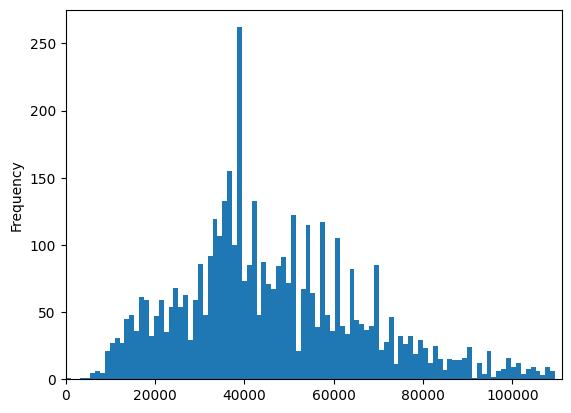

In [4]:
dfc["price"].plot(kind="hist", bins=100, xlim=[0, 111000])
print(f"Мода: {dfc["price"].mode()[0]}")
print(f"Медиана: {dfc["price"].median()}")
print(f"Среднее: {dfc["price"].mean()}")

<Axes: ylabel='Density'>

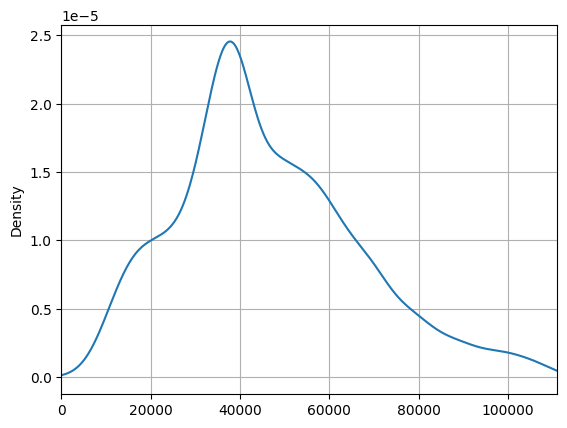

In [5]:
dfc["price"].plot(kind="kde", xlim=[0, 111000], grid=True)

<Axes: ylabel='Density'>

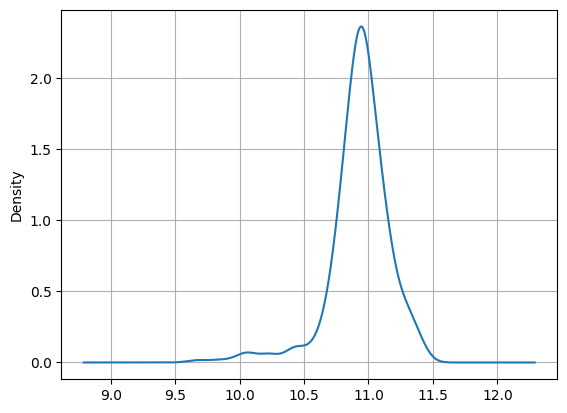

In [6]:
df_one_brand = dfc[dfc['brand'] == 'Chevrolet']

np.log1p(df_one_brand['price']).plot(kind='kde', grid=True)